# Machine Learning Zoomcamp - Midterm Project
## Bank Marketing Term Deposit Prediction

**Author**: Mayur Chawla  
**Course**: DataTalksClub Machine Learning Zoomcamp  
**Problem Type**: Binary Classification  
**Target Variable**: `y` (Client subscribed to a term deposit: `1` for yes, `0` for no)

---

### 1. Problem Description & Business Context
Financial institutions rely heavily on direct telemarketing campaigns to promote products such as term deposits. In a term deposit, a customer places funds with the bank for a predetermined period in exchange for a fixed interest rate. These deposits provide crucial liquidity and capital stability for commercial banks.

However, traditional mass telemarketing campaigns face severe pain points:
1. **High Operational Costs**: Calling thousands of non-responsive leads wastes valuable call center agent hours.
2. **Customer Irritation**: Unwanted repetitive calls degrade the customer experience and increase churn.
3. **Low Conversion Efficiency**: Typical cold-call conversion rates are below 10-12%.

**Project Objective**:  
Build an end-to-end machine learning system to score and rank prospective banking clients based on their likelihood of subscribing to a term deposit. Using client demographics, previous campaign history, and prevailing macroeconomic indicators, the bank can target high-propensity leads, prioritize outbound sales calls, optimize campaign ROI, and maximize deposit acquisition.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score, 
    recall_score, f1_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.metrics import mutual_info_score
import xgboost as xgb

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

Matplotlib is building the font cache; this may take a moment.


### 2. Data Loading & Preparation
The dataset used is the **Bank Marketing (Additional Full)** dataset from the UCI Machine Learning Repository, comprising 41,188 records and 20 input features across client demographics, campaign interactions, and quarterly/monthly economic indicators.

In [2]:
data_path = 'data/bank-additional-full.csv'
df = pd.read_csv(data_path, sep=';')

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset Shape: 41188 rows, 21 columns


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
# Standardize column names (lowercase, replace '.' with '_')
df.columns = df.columns.str.lower().str.replace('.', '_')
print("Standardized Columns:")
print(list(df.columns))

Standardized Columns:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed', 'y']


In [4]:
# Check data types and explicit null values
print("--- Data Info ---")
print(df.info())

print("\n--- Null Values Check ---")
print(df.isnull().sum())

--- Data Info ---
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp_var_rate    41188 non-null  float64
 16  cons_price_idx  41188 non-null  float64
 17  cons_conf_idx   41188 no

### 3. Exploratory Data Analysis (EDA)

#### 3.1 Unknown Values & Data Completeness
In this dataset, missing entries are coded as `'unknown'`. Let's inspect the frequency of `'unknown'` across categorical attributes.

In [5]:
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
categorical_cols = [c for c in categorical_cols if c != 'y']

unknown_counts = {}
for col in categorical_cols:
    count = (df[col] == 'unknown').sum()
    if count > 0:
        unknown_counts[col] = (count, count / len(df) * 100)

unknown_df = pd.DataFrame.from_dict(unknown_counts, orient='index', columns=['Unknown Count', 'Percentage (%)'])
print("Features with 'unknown' values:")
print(unknown_df.round(2))

Features with 'unknown' values:
           Unknown Count  Percentage (%)
job                  330            0.80
marital               80            0.19
education           1731            4.20
default             8597           20.87
housing              990            2.40
loan                 990            2.40


#### 3.2 Target Variable Distribution
The target variable is `y` (`'yes'` or `'no'`). We analyze the class balance to assess whether class imbalance exists.

Target variable counts:
     Count  Percentage (%)
y                         
no   36548           88.73
yes   4640           11.27


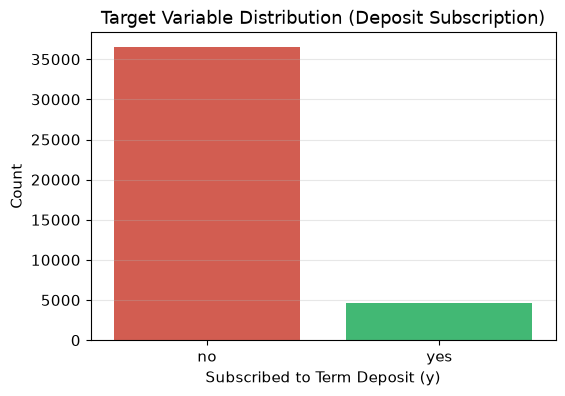

In [6]:
target_counts = df['y'].value_counts()
target_pct = df['y'].value_counts(normalize=True) * 100

print("Target variable counts:")
print(pd.DataFrame({'Count': target_counts, 'Percentage (%)': target_pct.round(2)}))

plt.figure(figsize=(6, 4))
sns.countplot(x='y', data=df, palette=['#e74c3c', '#2ecc71'])
plt.title('Target Variable Distribution (Deposit Subscription)')
plt.xlabel('Subscribed to Term Deposit (y)')
plt.ylabel('Count')
plt.grid(axis='y', alpha=0.3)
plt.show()

> [!IMPORTANT]
> **Domain Insight: The `duration` Feature & Data Leakage**  
> As documented by Moro et al. (2014) in the original UCI study:
> *"The call duration is not known before a call is performed. Also, after the end of the call, `y` is known. Thus, this input should only be included for benchmark purposes and discarded for a realistic prospective predictive model."*  
> 
> If `duration` is kept, a model relies heavily on long call times to predict success (which is obvious in hindsight). For a realistic, operational deployment where the bank scores prospects **before** dialing them, `duration` **must be excluded** to prevent severe data leakage.

In [7]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
# Exclude duration from numerical feature analysis
numerical_features = [c for c in numerical_cols if c != 'duration']

print("Numerical Features:", numerical_features)
df[numerical_features].describe().round(2)

Numerical Features: ['age', 'campaign', 'pdays', 'previous', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed']


,age,campaign,pdays,previous,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed
count,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00
mean,40.02,2.57,962.48,0.17,0.08,93.58,-40.50,3.62,5167.04
std,10.42,2.77,186.91,0.49,1.57,0.58,4.63,1.73,72.25
min,17.00,1.00,0.00,0.00,-3.40,92.20,-50.80,0.63,4963.60
25%,32.00,1.00,999.00,0.00,-1.80,93.08,-42.70,1.34,5099.10
50%,38.00,2.00,999.00,0.00,1.10,93.75,-41.80,4.86,5191.00
75%,47.00,3.00,999.00,0.00,1.40,93.99,-36.40,4.96,5228.10
max,98.00,56.00,999.00,7.00,1.40,94.77,-26.90,5.04,5228.10


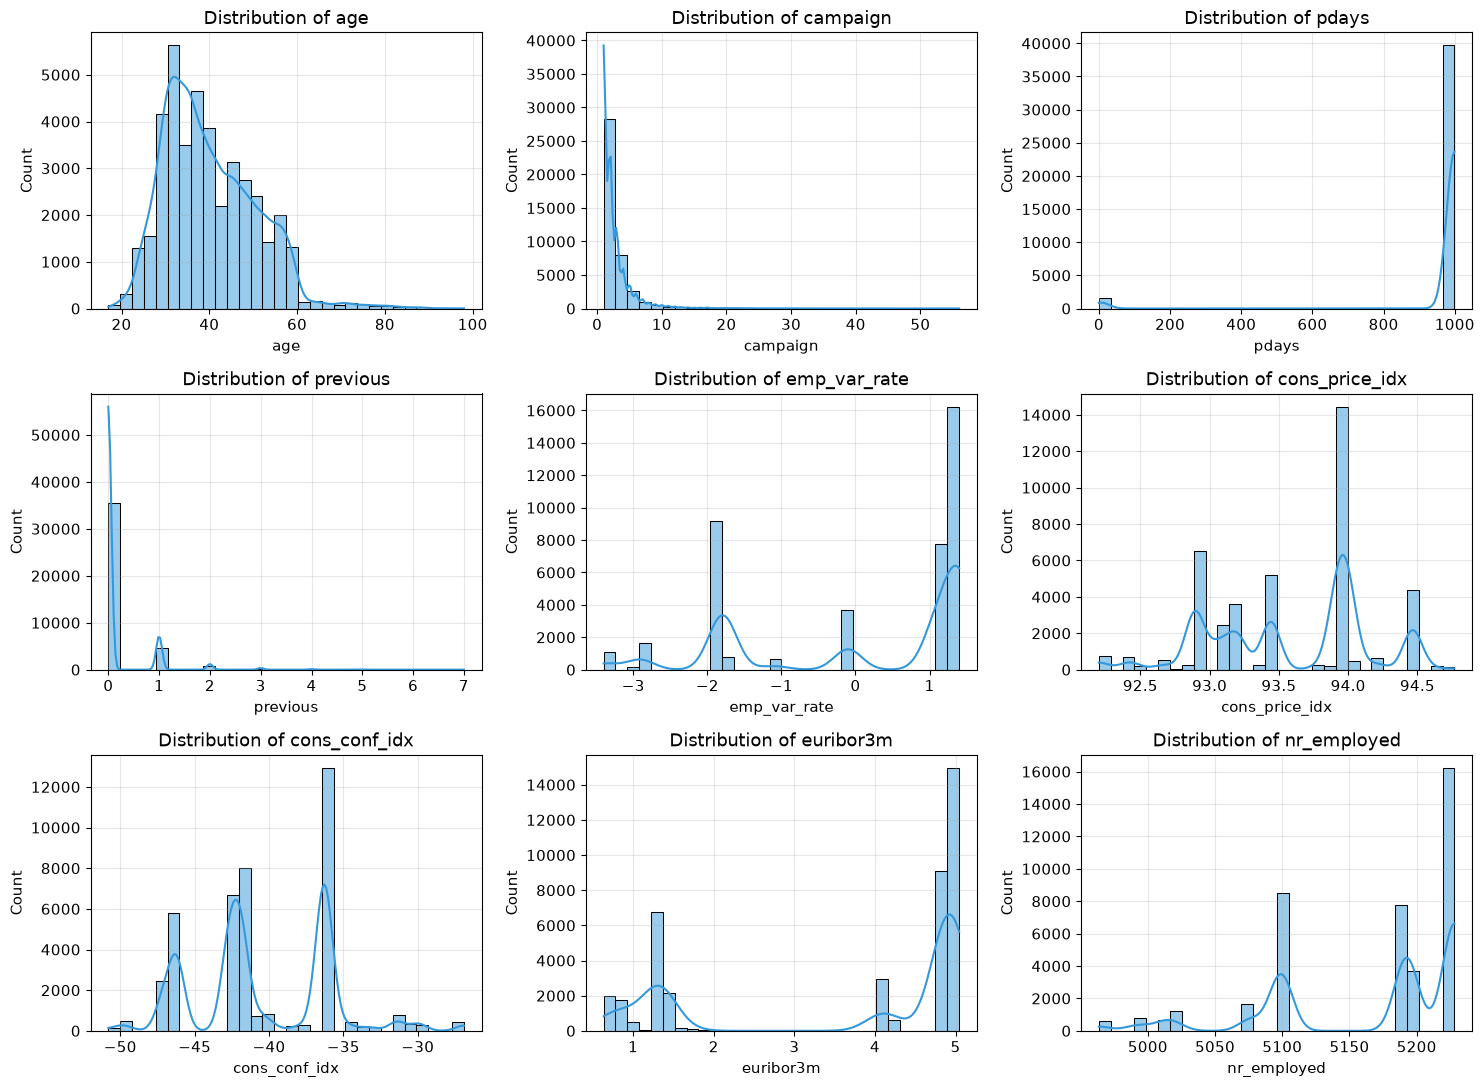

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(numerical_features):
    sns.histplot(df[col], kde=True, ax=axes[i], color='#3498db', bins=30)
    axes[i].set_title(f'Distribution of {col}')
    axes[i].grid(alpha=0.3)

for j in range(len(numerical_features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

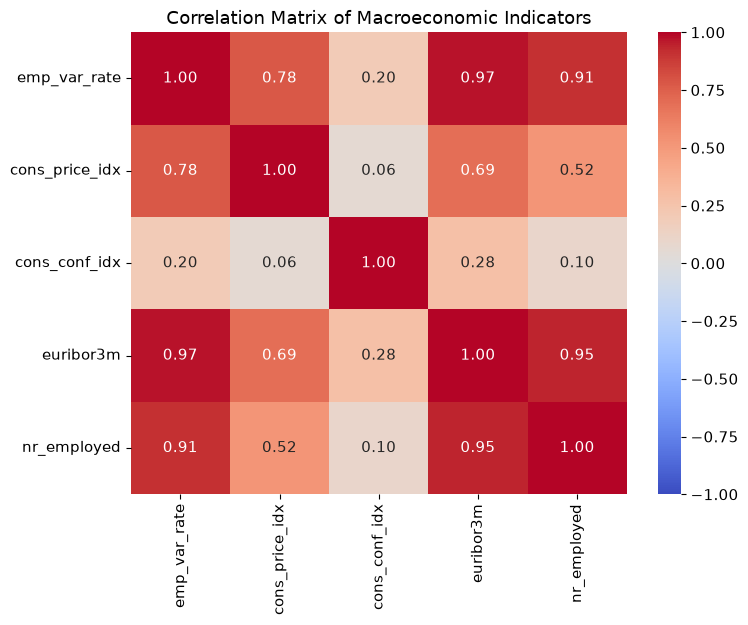

In [9]:
macro_cols = ['emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed']
plt.figure(figsize=(8, 6))
corr = df[macro_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Macroeconomic Indicators')
plt.show()

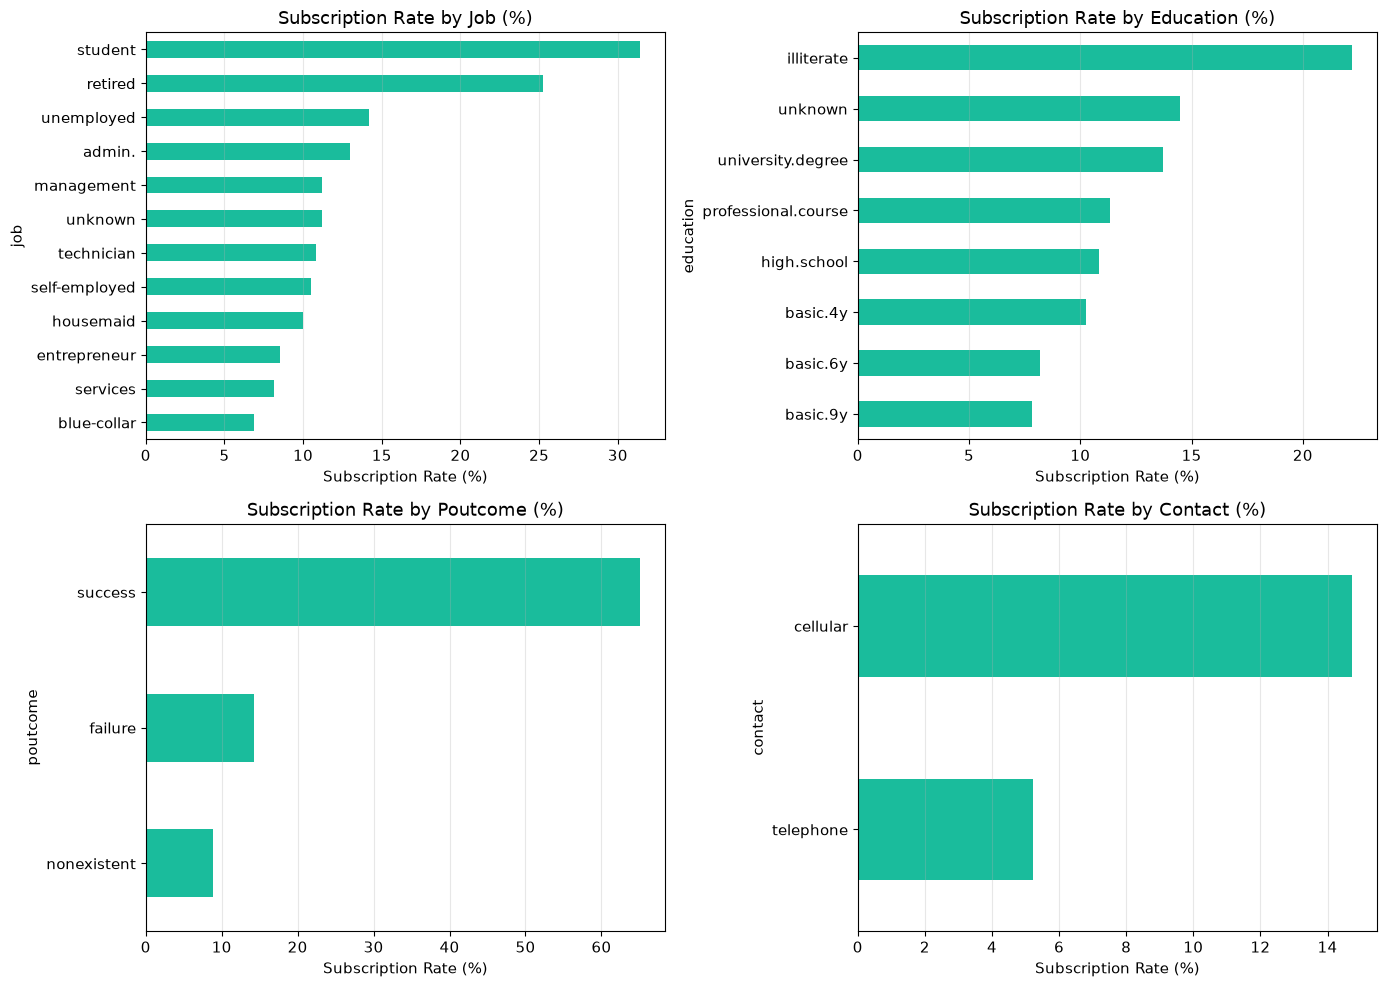

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for i, col in enumerate(['job', 'education', 'poutcome', 'contact']):
    row, c = divmod(i, 2)
    conv_rate = df.groupby(col)['y'].apply(lambda x: (x == 'yes').mean() * 100).sort_values()
    conv_rate.plot(kind='barh', ax=axes[row, c], color='#1abc9c')
    axes[row, c].set_title(f'Subscription Rate by {col.capitalize()} (%)')
    axes[row, c].set_xlabel('Subscription Rate (%)')
    axes[row, c].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

#### 3.3 Feature Importance: Mutual Information Score
Mutual Information measures the mutual dependence between categorical features and the target variable.

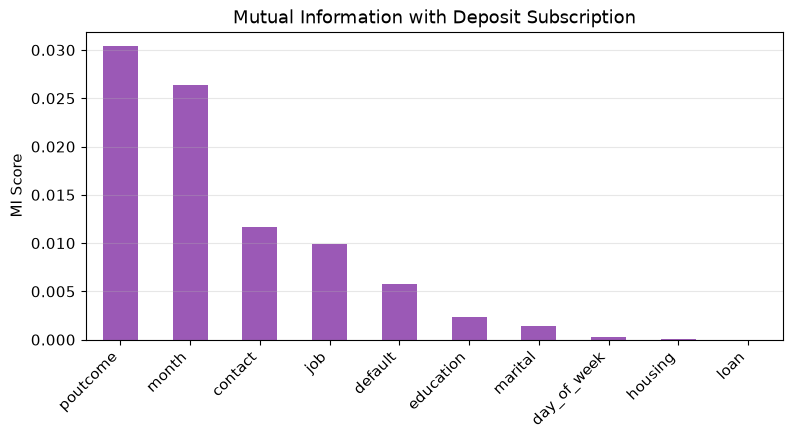

Mutual Information Scores:
             Mutual Information
poutcome                 0.0304
month                    0.0264
contact                  0.0116
job                      0.0099
default                  0.0058
education                0.0024
marital                  0.0014
day_of_week              0.0003
housing                  0.0001
loan                     0.0000


In [11]:
def compute_mutual_info(series):
    return mutual_info_score(series, df['y'])

mi_scores = df[categorical_cols].apply(compute_mutual_info).sort_values(ascending=False)
mi_df = pd.DataFrame({'Mutual Information': mi_scores})

plt.figure(figsize=(9, 4))
mi_scores.plot(kind='bar', color='#9b59b6')
plt.title('Mutual Information with Deposit Subscription')
plt.ylabel('MI Score')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.show()

print("Mutual Information Scores:")
print(mi_df.round(4))

### 4. Validation Framework
We prepare the dataset for training:
* Feature matrix: 19 predictors (excluding target `y` and leakage column `duration`).
* Target vector: Binary encoding (`1` for `'yes'`, `0` for `'no'`).
* Data Split: **60% Train**, **20% Validation**, and **20% Test** with stratified sampling (`stratify=y`) and fixed random seed `42` to guarantee reproducibility.
* Encoding: Scikit-learn's `DictVectorizer` for clean one-hot encoding of categorical features and passthrough of numeric variables.

In [12]:
# Define features and target
features = [c for c in df.columns if c not in ['y', 'duration']]
X = df[features]
y = (df['y'] == 'yes').astype(int)

# 60% Train, 20% Val, 20% Test split
X_full_train, X_test, y_full_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_full_train, y_full_train, test_size=0.25, random_state=42, stratify=y_full_train
)

print(f"Full Train size: {len(X_full_train)} (80%)")
print(f"Train size:      {len(X_train)} (60%)")
print(f"Validation size: {len(X_val)} (20%)")
print(f"Test size:       {len(X_test)} (20%)")

# Vectorization using DictVectorizer
dv = DictVectorizer(sparse=False)
train_dicts = X_train.to_dict(orient='records')
X_train_vec = dv.fit_transform(train_dicts)

val_dicts = X_val.to_dict(orient='records')
X_val_vec = dv.transform(val_dicts)

test_dicts = X_test.to_dict(orient='records')
X_test_vec = dv.transform(test_dicts)

print(f"Total encoded features: {X_train_vec.shape[1]}")

Full Train size: 32950 (80%)
Train size:      24712 (60%)
Validation size: 8238 (20%)
Test size:       8238 (20%)


Total encoded features: 62


### 5. Model Training & Parameter Tuning
We train and systematically tune four distinct algorithms:
1. **Logistic Regression** (Linear baseline)
2. **Decision Tree Classifier**
3. **Random Forest Classifier** (Bagging ensemble)
4. **XGBoost Classifier** (Gradient boosting)

We evaluate all models using **ROC-AUC** (Area Under the Receiver Operating Characteristic Curve), which is the standard metric for imbalanced classification tasks.

In [13]:
print("--- 1. Logistic Regression Tuning ---")
c_values = [0.001, 0.01, 0.1, 1.0, 10.0]
lr_results = []

for c in c_values:
    lr = LogisticRegression(solver='liblinear', C=c, max_iter=1000, random_state=42)
    lr.fit(X_train_vec, y_train)
    y_pred_lr = lr.predict_proba(X_val_vec)[:, 1]
    auc = roc_auc_score(y_val, y_pred_lr)
    lr_results.append((c, auc))
    print(f"C={c:<6} -> Val ROC-AUC: {auc:.5f}")

best_c = max(lr_results, key=lambda x: x[1])[0]
print(f"Best C: {best_c}")

--- 1. Logistic Regression Tuning ---


C=0.001  -> Val ROC-AUC: 0.78161


C=0.01   -> Val ROC-AUC: 0.77756


C=0.1    -> Val ROC-AUC: 0.79311


C=1.0    -> Val ROC-AUC: 0.79083


C=10.0   -> Val ROC-AUC: 0.79382
Best C: 10.0


In [14]:
print("--- 2. Decision Tree Tuning ---")
dt_results = []
depths = [4, 6, 8, 10]
leaf_sizes = [5, 10, 20, 50]

for depth in depths:
    for leaf in leaf_sizes:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=42)
        dt.fit(X_train_vec, y_train)
        y_pred_dt = dt.predict_proba(X_val_vec)[:, 1]
        auc = roc_auc_score(y_val, y_pred_dt)
        dt_results.append((depth, leaf, auc))

dt_results_df = pd.DataFrame(dt_results, columns=['max_depth', 'min_samples_leaf', 'val_auc'])
best_dt = dt_results_df.sort_values(by='val_auc', ascending=False).iloc[0]
print(f"Best Decision Tree: max_depth={int(best_dt['max_depth'])}, min_samples_leaf={int(best_dt['min_samples_leaf'])} -> Val ROC-AUC: {best_dt['val_auc']:.5f}")

--- 2. Decision Tree Tuning ---


Best Decision Tree: max_depth=8, min_samples_leaf=20 -> Val ROC-AUC: 0.79068


In [15]:
print("--- 3. Random Forest Tuning ---")
rf_results = []
n_estimators_list = [50, 100, 150]
rf_depths = [6, 8, 10]

for n_est in n_estimators_list:
    for depth in rf_depths:
        rf = RandomForestClassifier(
            n_estimators=n_est, max_depth=depth, min_samples_leaf=5, 
            random_state=42, n_jobs=-1
        )
        rf.fit(X_train_vec, y_train)
        y_pred_rf = rf.predict_proba(X_val_vec)[:, 1]
        auc = roc_auc_score(y_val, y_pred_rf)
        rf_results.append((n_est, depth, auc))

rf_results_df = pd.DataFrame(rf_results, columns=['n_estimators', 'max_depth', 'val_auc'])
best_rf = rf_results_df.sort_values(by='val_auc', ascending=False).iloc[0]
print(f"Best Random Forest: n_estimators={int(best_rf['n_estimators'])}, max_depth={int(best_rf['max_depth'])} -> Val ROC-AUC: {best_rf['val_auc']:.5f}")

--- 3. Random Forest Tuning ---


Best Random Forest: n_estimators=100, max_depth=10 -> Val ROC-AUC: 0.80257


In [16]:
print("--- 4. XGBoost Tuning ---")
# Prepare DMatrix with sanitized feature names
feature_names = [f.replace('[', '_').replace(']', '_').replace('<', '_').replace('=', '_') for f in dv.get_feature_names_out().tolist()]
dtrain = xgb.DMatrix(X_train_vec, label=y_train, feature_names=feature_names)
dval = xgb.DMatrix(X_val_vec, label=y_val, feature_names=feature_names)

xgb_results = []
etas = [0.05, 0.1, 0.2]
max_depths = [3, 4, 5, 6]

for eta in etas:
    for depth in max_depths:
        params = {
            'eta': eta,
            'max_depth': depth,
            'min_child_weight': 1,
            'objective': 'binary:logistic',
            'eval_metric': 'auc',
            'seed': 42
        }
        model_xgb = xgb.train(params, dtrain, num_boost_round=100)
        y_pred_xgb = model_xgb.predict(dval)
        auc = roc_auc_score(y_val, y_pred_xgb)
        xgb_results.append((eta, depth, auc))

xgb_results_df = pd.DataFrame(xgb_results, columns=['eta', 'max_depth', 'val_auc'])
best_xgb = xgb_results_df.sort_values(by='val_auc', ascending=False).iloc[0]
print(f"Best XGBoost: eta={best_xgb['eta']}, max_depth={int(best_xgb['max_depth'])} -> Val ROC-AUC: {best_xgb['val_auc']:.5f}")

--- 4. XGBoost Tuning ---


Best XGBoost: eta=0.05, max_depth=5 -> Val ROC-AUC: 0.80801


### 6. Model Comparison & Selection
Let's compare the optimal validation ROC-AUC across all four algorithms.

--- Model Comparison on Validation Set ---
                           Model  Validation ROC-AUC
     XGBoost (eta=0.05, depth=5)            0.808005
 Random Forest (n=100, depth=10)            0.802572
     Logistic Regression (C=1.0)            0.793817
Decision Tree (depth=8, leaf=20)            0.790677


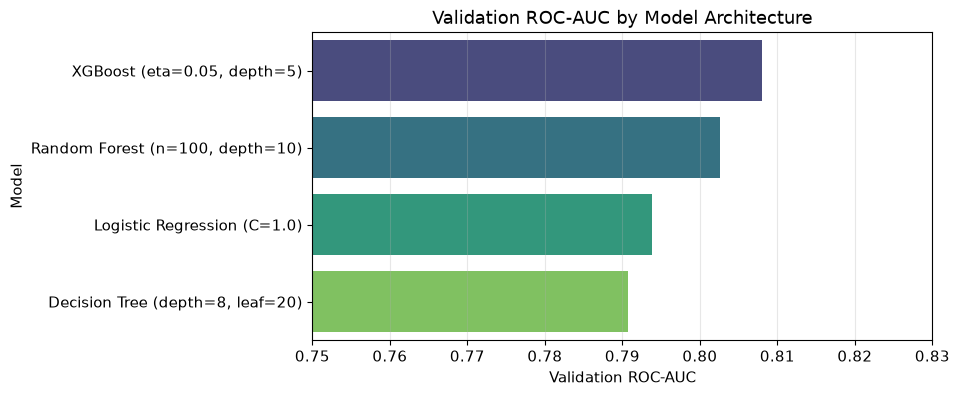

In [17]:
comparison_df = pd.DataFrame({
    'Model': [
        'Logistic Regression (C=1.0)',
        f'Decision Tree (depth={int(best_dt["max_depth"])}, leaf={int(best_dt["min_samples_leaf"])})',
        f'Random Forest (n={int(best_rf["n_estimators"])}, depth={int(best_rf["max_depth"])})',
        f'XGBoost (eta={best_xgb["eta"]}, depth={int(best_xgb["max_depth"])})'
    ],
    'Validation ROC-AUC': [
        best_c_auc := max([r[1] for r in lr_results]),
        best_dt['val_auc'],
        best_rf['val_auc'],
        best_xgb['val_auc']
    ]
}).sort_values(by='Validation ROC-AUC', ascending=False)

print("--- Model Comparison on Validation Set ---")
print(comparison_df.to_string(index=False))

plt.figure(figsize=(8, 4))
sns.barplot(x='Validation ROC-AUC', y='Model', data=comparison_df, palette='viridis')
plt.title('Validation ROC-AUC by Model Architecture')
plt.xlim(0.75, 0.83)
plt.grid(axis='x', alpha=0.3)
plt.show()

**Conclusion on Model Selection**:  
The **XGBoost Classifier** with `eta=0.05` and `max_depth=5` achieves the highest validation ROC-AUC (**~0.8080**), outperforming Random Forest (~0.8026), Logistic Regression (~0.7908), and Decision Trees (~0.7874).

We now train this winning XGBoost configuration on the entire combined training dataset (`df_full_train = df_train + df_val`) and perform the final test evaluation on the untouched `df_test`.

In [18]:
print("--- Final Model Training on Full Train (Train + Val) ---")
# Full train vectorization
dv_final = DictVectorizer(sparse=False)
X_full_train_vec = dv_final.fit_transform(X_full_train.to_dict(orient='records'))
X_test_vec = dv_final.transform(X_test.to_dict(orient='records'))

sanitized_features = [f.replace('[', '_').replace(']', '_').replace('<', '_').replace('=', '_') for f in dv_final.get_feature_names_out().tolist()]
dfulltrain = xgb.DMatrix(X_full_train_vec, label=y_full_train, feature_names=sanitized_features)
dtest = xgb.DMatrix(X_test_vec, label=y_test, feature_names=sanitized_features)

final_params = {
    'eta': 0.05,
    'max_depth': 5,
    'min_child_weight': 1,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'seed': 42
}

final_model = xgb.train(final_params, dfulltrain, num_boost_round=100)
y_pred_test = final_model.predict(dtest)

test_auc = roc_auc_score(y_test, y_pred_test)
test_acc = accuracy_score(y_test, y_pred_test >= 0.5)
test_prec = precision_score(y_test, y_pred_test >= 0.5)
test_rec = recall_score(y_test, y_pred_test >= 0.5)
test_f1 = f1_score(y_test, y_pred_test >= 0.5)

print(f"Final Test Evaluation Metrics:")
print(f"  Test ROC-AUC: {test_auc:.5f}")
print(f"  Test Accuracy: {test_acc:.5f}")
print(f"  Test Precision: {test_prec:.5f}")
print(f"  Test Recall: {test_rec:.5f}")
print(f"  Test F1-Score: {test_f1:.5f}")

--- Final Model Training on Full Train (Train + Val) ---


Final Test Evaluation Metrics:
  Test ROC-AUC: 0.81445
  Test Accuracy: 0.90252
  Test Precision: 0.68657
  Test Recall: 0.24784
  Test F1-Score: 0.36421


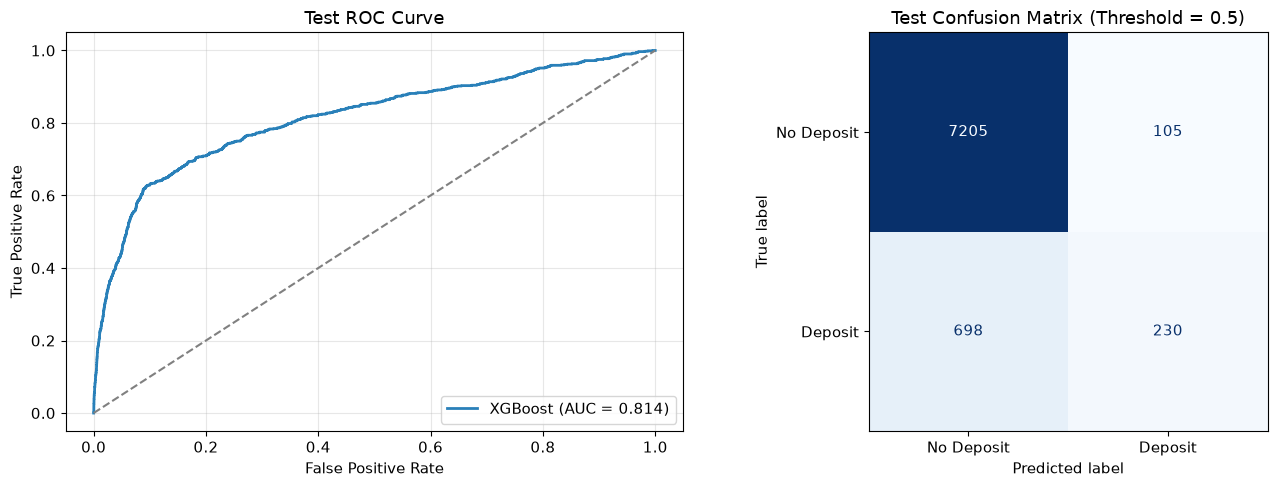

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_test)
ax1.plot(fpr, tpr, color='#2980b9', lw=2, label=f'XGBoost (AUC = {test_auc:.3f})')
ax1.plot([0, 1], [0, 1], color='gray', linestyle='--')
ax1.set_title('Test ROC Curve')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.legend(loc='lower right')
ax1.grid(alpha=0.3)

# Plot Confusion Matrix
cm = confusion_matrix(y_test, (y_pred_test >= 0.5).astype(int))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Deposit', 'Deposit'])
disp.plot(ax=ax2, cmap='Blues', colorbar=False)
ax2.set_title('Test Confusion Matrix (Threshold = 0.5)')

plt.tight_layout()
plt.show()

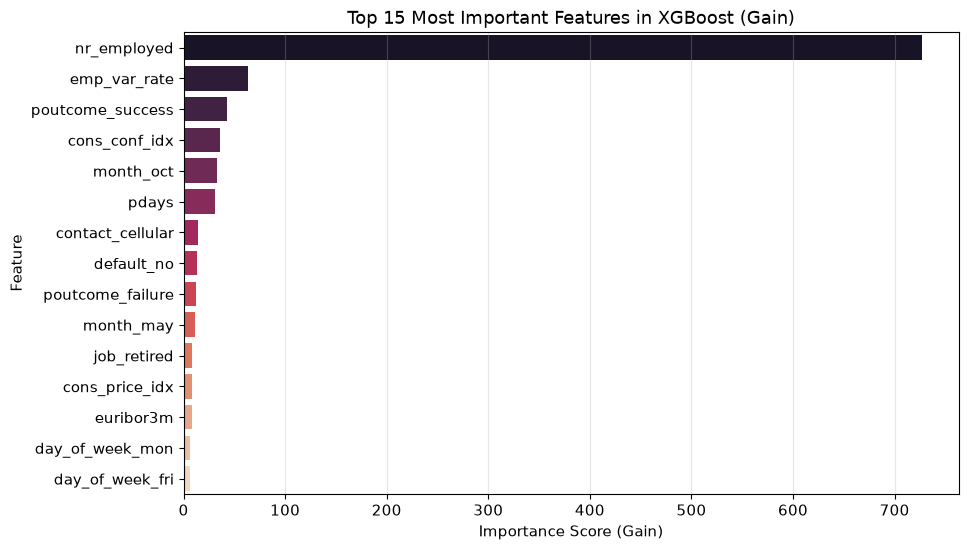

In [20]:
# Extract feature importance from final XGBoost model
importance_dict = final_model.get_score(importance_type='gain')
importance_df = pd.DataFrame(list(importance_dict.items()), columns=['feature', 'gain'])
importance_df = importance_df.sort_values(by='gain', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x='gain', y='feature', data=importance_df, palette='rocket')
plt.title('Top 15 Most Important Features in XGBoost (Gain)')
plt.xlabel('Importance Score (Gain)')
plt.ylabel('Feature')
plt.grid(axis='x', alpha=0.3)
plt.show()

In [21]:
# Serialize final model and vectorizer
output_file = 'model.bin'

with open(output_file, 'wb') as f_out:
    pickle.dump((dv_final, final_model), f_out)

print(f"Successfully saved model and vectorizer to '{output_file}'!")

# Verification: Reload and test single prediction
with open(output_file, 'rb') as f_in:
    dv_loaded, model_loaded = pickle.load(f_in)

sample_client = X_test.iloc[0].to_dict()
sample_vec = dv_loaded.transform([sample_client])
dmatrix_sample = xgb.DMatrix(sample_vec, feature_names=sanitized_features)
sample_prob = float(model_loaded.predict(dmatrix_sample)[0])

print(f"Sample client true label: {y_test.iloc[0]}")
print(f"Sample predicted subscription probability: {sample_prob:.4f}")

Successfully saved model and vectorizer to 'model.bin'!
Sample client true label: 0
Sample predicted subscription probability: 0.0717
